<a href="https://colab.research.google.com/github/paggalih/project/blob/main/scvelo/cluster.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install scanpy scvelo cellrank --quiet
# !pip install "numpy<2" "anndata<0.11" scvelo
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd

# Patch: scVelo passes lists to pd.unique
_orig_unique = pd.unique
def _safe_unique(values):
    if isinstance(values, (list, tuple)):
        values = np.asarray(values, dtype=object)
    return _orig_unique(values)
pd.unique = _safe_unique

import scanpy as sc
import scvelo as scv
scv.settings.verbosity = 1

import numba

AnnData object with n_obs × n_vars = 3696 × 27998
    obs: 'clusters_coarse', 'clusters', 'S_score', 'G2M_score'
    var: 'highly_variable_genes'
    uns: 'clusters_coarse_colors', 'clusters_colors', 'day_colors', 'neighbors', 'pca'
    obsm: 'X_pca', 'X_umap'
    obsp: 'distances', 'connectivities'
    layers: 'spliced', 'unspliced', None (.X)
clusters
Ductal           916
Ngn3 high EP     642
Pre-endocrine    592
Beta             591
Alpha            481
Ngn3 low EP      262
Epsilon          142
Delta             70
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


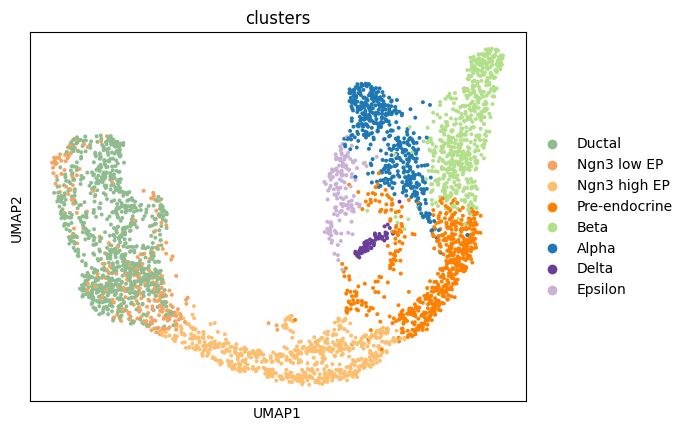

AnnData object with n_obs × n_vars = 3696 × 2000
    obs: 'clusters_coarse', 'clusters', 'S_score', 'G2M_score', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts'
    var: 'highly_variable_genes', 'gene_count_corr', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'clusters_coarse_colors', 'clusters_colors', 'day_colors', 'neighbors', 'pca', 'log1p', 'hvg', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: 'spliced', 'unspliced', None (.X), 'Ms', 'Mu'


In [ ]:
import scanpy as sc
import scvelo as scv

adata = scv.datasets.pancreas()
print(adata)
print(adata.obs["clusters"].value_counts())

scv.pp.filter_and_normalize(adata, min_shared_counts=20)

if "log1p" not in adata.uns:
    sc.pp.log1p(adata)

sc.pp.highly_variable_genes(adata, n_top_genes=2000, subset=True)

sc.tl.pca(adata)
sc.pp.neighbors(adata, n_pcs=30, n_neighbors=30)
scv.pp.moments(adata)

sc.tl.umap(adata)
sc.pl.umap(adata, color="clusters", save="_clusters.png")
print(adata)

/usr/local/lib/python3.13/dist-packages/scvelo/tools/optimization.py:184: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  gamma[i] = np.linalg.pinv(A.T.dot(A)).dot(A.T.dot(y[:, i]))
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  0%|          | 0/3696 [00:00<?, ?cells/s]

/usr/lib/python3.13/multiprocessing/popen_fork.py:73: DeprecationWarning: This process (pid=42180) is multi-threaded, use of fork() may lead to deadlocks in the child.
  self.pid = os.fork()
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a futu

saving figure to file ./figures/scvelo_velocity_stochastic.png


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


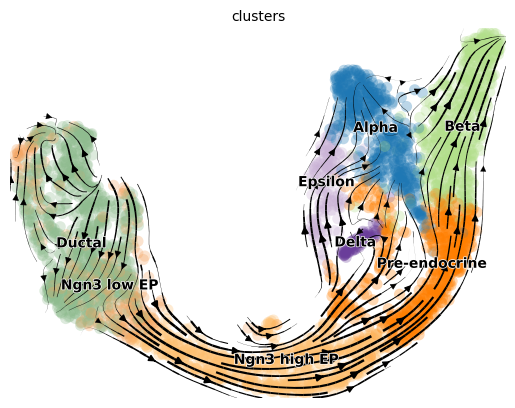

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  0%|          | 0/1036 [00:00<?, ?gene/s]

/usr/lib/python3.13/multiprocessing/popen_fork.py:73: DeprecationWarning: This process (pid=42180) is multi-threaded, use of fork() may lead to deadlocks in the child.
  self.pid = os.fork()
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  0%|          | 0/3696 [00:00<?, ?cells/s]

/usr/lib/python3.13/multiprocessing/popen_fork.py:73: DeprecationWarning: This process (pid=42180) is multi-threaded, use of fork() may lead to deadlocks in the child.
  self.pid = os.fork()
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a futu

saving figure to file ./figures/scvelo_velocity_dynamical.png


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


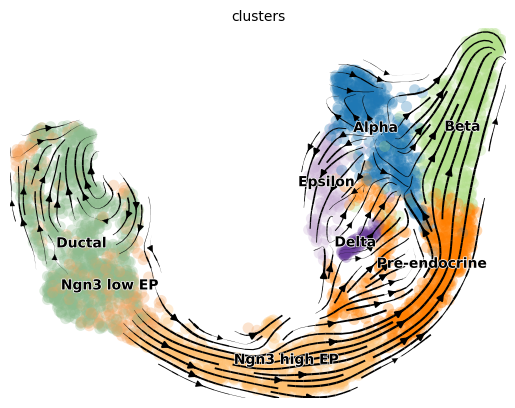

saving figure to file ./figures/scvelo_latent_time.png


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


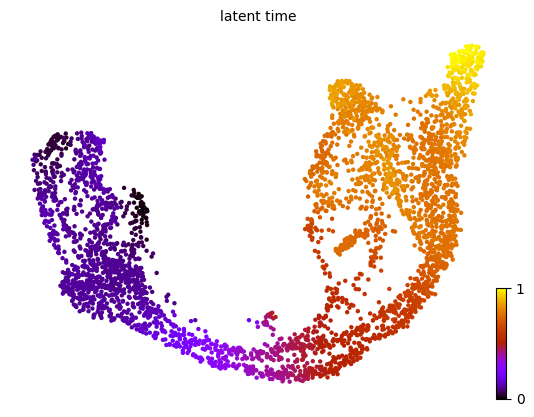

saving figure to file ./figures/scvelo_phase_portraits.png


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


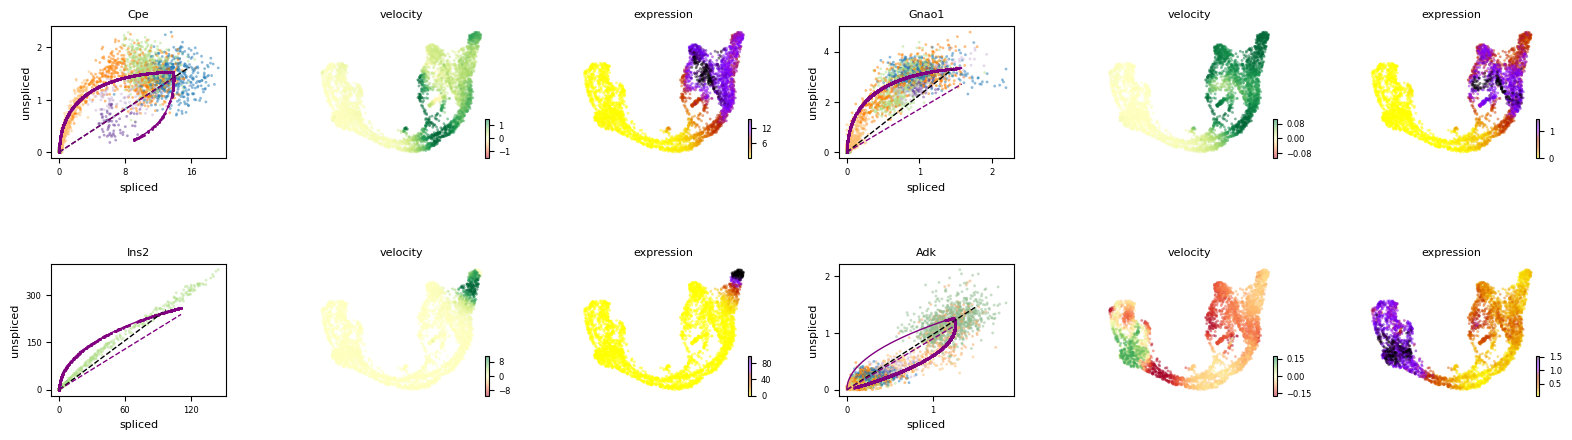

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# 1. Fast model first
scv.tl.velocity(adata, mode="stochastic")
scv.tl.velocity_graph(adata)
scv.pl.velocity_embedding_stream(
    adata, basis="umap", color="clusters",
    save="velocity_stochastic.png"
)

# 2. Dynamical model (slower, ~5–10 min)
scv.tl.recover_dynamics(adata, n_jobs=2)
scv.tl.velocity(adata, mode="dynamical")
scv.tl.velocity_graph(adata)
scv.pl.velocity_embedding_stream(
    adata, basis="umap", color="clusters",
    save="velocity_dynamical.png"
)
# 3. Latent time
scv.tl.latent_time(adata)
scv.pl.scatter(
    adata, color="latent_time", color_map="gnuplot",
    size=40, save="latent_time.png"
)
# 4. Phase portraits: u vs s per gene
scv.pl.velocity(
    adata, ["Cpe", "Gnao1", "Ins2", "Adk"],
    ncols=2, save="phase_portraits.png"
)
# 5. Save progress
adata.write("pancreas_velocity.h5ad")

INFO     Computing transition matrix using 'deterministic' model                                                   


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  0%|          | 0/3696 [00:00<?, ?cell/s]

/usr/lib/python3.13/multiprocessing/popen_fork.py:73: DeprecationWarning: This process (pid=42180) is multi-threaded, use of fork() may lead to deadlocks in the child.
  self.pid = os.fork()
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a futu

INFO     Using `softmax_scale=4.9780`                                                                              


...

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


  0%|          | 0/2 [00:00<?, ?/s]

/usr/lib/python3.13/multiprocessing/popen_fork.py:73: DeprecationWarning: This process (pid=42180) is multi-threaded, use of fork() may lead to deadlocks in the child.
  self.pid = os.fork()


INFO     Adding `adata.obsm['lineages_fwd']`                                                                       
                `.fate_probabilities`                                                                              
             Finish (0.33s)                                                                                        
INFO     Adding `adata.varm['terminal_lineage_drivers']`                                                           
                `.lineage_drivers`                                                                                 
             Finish (0.11s)                                                                                        
          Epsilon_corr  Epsilon_pval  Epsilon_qval  Epsilon_ci_low  \
index                                                                
Nkx6-1       -0.268943  5.138095e-63  3.113997e-61       -0.298595   
Npepl1       -0.268543  7.983984e-63  4.696461e-61       -0.298202   
Hnrnpa1      -0.263605  

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
/usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarni

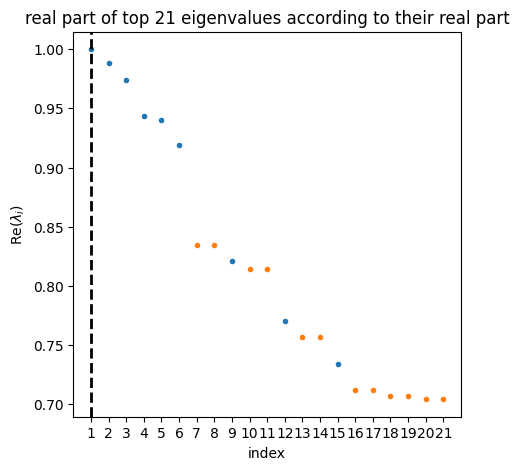

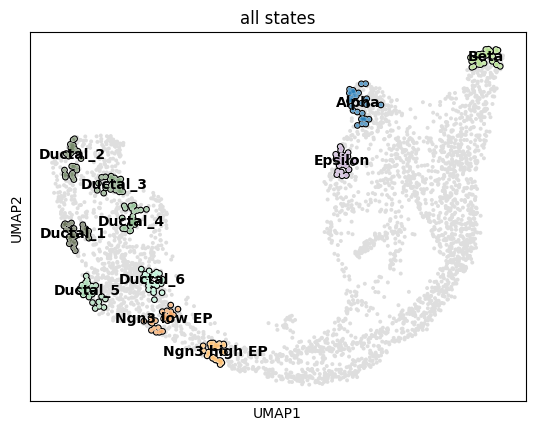

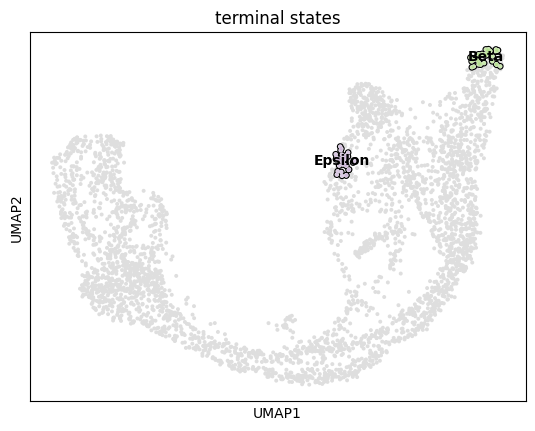

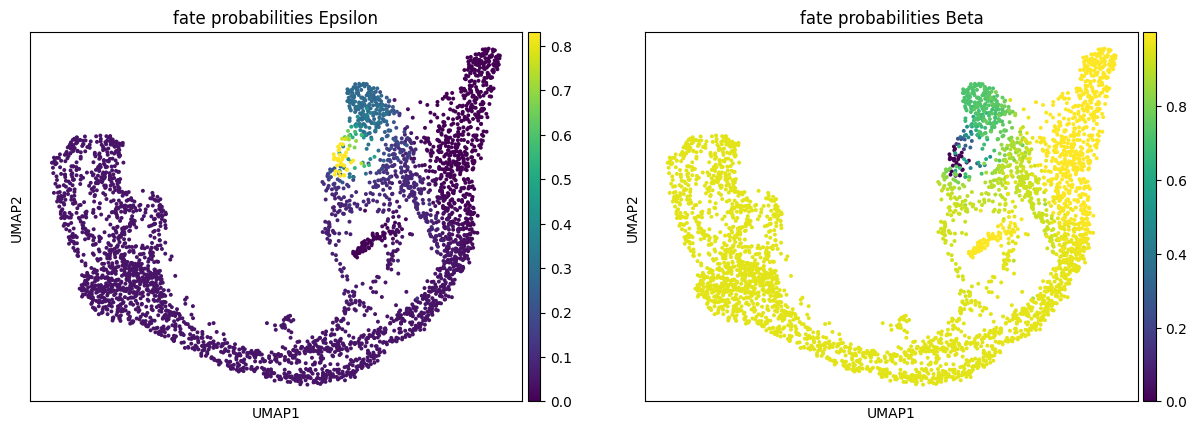

In [5]:
import cellrank as cr

# 1. Build transition matrix
vk = cr.kernels.VelocityKernel(adata).compute_transition_matrix()
ck = cr.kernels.ConnectivityKernel(adata).compute_transition_matrix()
kernel = 0.8 * vk + 0.2 * ck
print(kernel)

# 2. Estimator + spectrum
g = cr.estimators.GPCCA(kernel)
g.compute_schur(n_components=20)
g.plot_spectrum(real_only=True, save="spectrum.png")

# 3. Macrostates
g.compute_macrostates(n_states=10, cluster_key="clusters")
g.plot_macrostates(which="all", save="macrostates.png")

# 4. Terminal states
g.predict_terminal_states()
g.plot_macrostates(which="terminal", save="terminal.png")

# 5. Fate probabilities
g.compute_fate_probabilities()
g.plot_fate_probabilities(same_plot=False, save="fates.png")

# 6. Driver genes for Beta
drivers = g.compute_lineage_drivers(cluster_key="clusters")
print(drivers.sort_values("Beta_corr", ascending=False).head(10))